***LAB 08***

**KNN CLASSIFIER**

Load dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [2]:
data = load_breast_cancer(as_frame=True).frame
print(data.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

Load dataset from CSV (alternative)

In [3]:
#save the dataset to csv
data.to_csv('breast_cancer.csv', index=False)

#load the dataset from csv (for your own file just change the file name/path)
data = pd.read_csv('breast_cancer.csv')
print(data.shape)

(569, 31)


Data preprocessing

In [4]:
#missing values
print(data.isnull().sum().sum())
data = data.fillna(data.median(numeric_only=True))

#encode categorical data (this dataset has none; this line works for any csv)
cat_cols = data.select_dtypes(include='object').columns
data = pd.get_dummies(data, columns=cat_cols, drop_first=True)

0


In [5]:
X = data.drop(columns='target')
y = data['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#KNN works on distances so features must be scaled
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Train KNN with different values of K (3, 5, 7)

In [6]:
rows = []
for k in [3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    rows.append([k,
                 accuracy_score(y_test, y_pred),
                 precision_score(y_test, y_pred),
                 recall_score(y_test, y_pred),
                 f1_score(y_test, y_pred)])

print(pd.DataFrame(rows, columns=['K', 'Accuracy', 'Precision', 'Recall', 'F1-score']).round(3))

   K  Accuracy  Precision  Recall  F1-score
0  3     0.982      0.973   1.000     0.986
1  5     0.956      0.959   0.972     0.966
2  7     0.974      0.960   1.000     0.980


              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



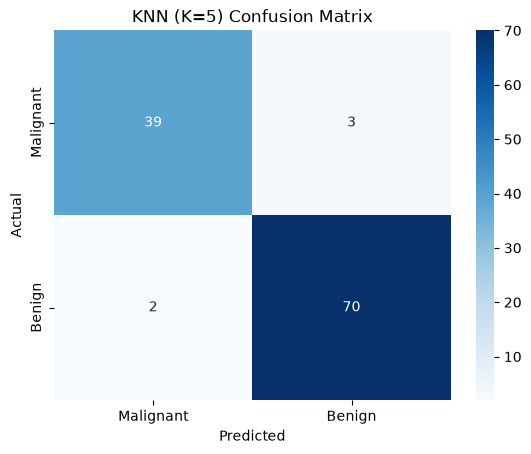

In [7]:
#detailed report and confusion matrix for K=5
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
y_pred = knn.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Malignant','Benign']))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant','Benign'], yticklabels=['Malignant','Benign'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('KNN (K=5) Confusion Matrix')
plt.show()

Test how accuracy changes with different values of K

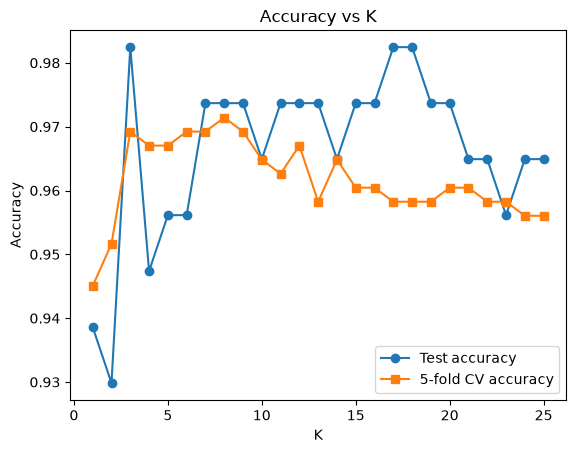

Best K from cross validation = 8


In [8]:
ks = range(1, 26)
test_acc, cv_acc = [], []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    test_acc.append(m.score(X_test, y_test))
    cv_acc.append(cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean())

plt.plot(ks, test_acc, marker='o', label='Test accuracy')
plt.plot(ks, cv_acc, marker='s', label='5-fold CV accuracy')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('Accuracy vs K')
plt.legend()
plt.show()

best_k = ks[int(np.argmax(cv_acc))]
print('Best K from cross validation =', best_k)

Small K (like 1) is sensitive to noise and can overfit, while a very large K makes the decision boundary too smooth and can underfit. Accuracy stays high and fairly stable for K between about 3 and 15 here.

The best K is chosen using cross validation on the training data (not the test data), which is the correct way to select K.